# Online Retail: agrupamiento de líneas de venta
**Cano Vargas Abraham · Tópicos de Big Data**

En esta segunda práctica quiero distinguir compras de pocas o muchas unidades y artículos con precios diferentes. Cada observación es una **línea de factura**. Aunque utilice el mismo archivo de ventas, el resultado no representa grupos de clientes.

Se conservan los criterios del ejercicio: quitar nulos y duplicados, `Quantity > 0`, `UnitPrice >= 1`, seleccionar cantidad y precio, aplicar logaritmo natural, estandarizar y comparar K-Means.

**Fuente:** Chen, D. (2015), [Online Retail, UCI](https://doi.org/10.24432/C5BW33), CC BY 4.0. El CSV se convirtió del Excel original sin filtrar filas. El precio se expresa en libras esterlinas. Código e interpretación elaborados para esta práctica a partir de los objetivos de clase.


## 1. Revisar el archivo


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import silhouette_score

pd.set_option('display.max_columns', None)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True,
                     'grid.alpha': 0.2, 'figure.dpi': 110})
SEMILLA = 42
# Permite ejecutar desde notebooks/, desde U4_1_Clustering/ o desde la raíz del repo.
candidatas = [Path('../data/raw/online_retail.csv'), Path('data/raw/online_retail.csv'),
              Path('U4_1_Clustering/data/raw/online_retail.csv')]
ruta = next((p for p in candidatas if p.exists()), None)
if ruta is None:
    raise FileNotFoundError('Coloca online_retail.csv en U4_1_Clustering/data/raw/.')
carpeta = ruta.parent.parent.parent
salidas = carpeta / 'outputs'
salidas.mkdir(exist_ok=True)
ventas = pd.read_csv(ruta, dtype={'InvoiceNo':'string', 'StockCode':'string'}, encoding='utf-8-sig')
print('Dimensiones originales:', ventas.shape)
display(ventas.head())


Dimensiones originales: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
display(pd.DataFrame({'Tipo':ventas.dtypes.astype(str), 'Nulos':ventas.isna().sum()}))
print('Duplicados exactos:', ventas.duplicated().sum())
print('Cantidades no positivas:', ventas['Quantity'].le(0).sum())
print('Precios no positivos:', ventas['UnitPrice'].le(0).sum())
print('Cancelaciones:', ventas['InvoiceNo'].str.upper().str.startswith('C', na=False).sum())
display(ventas[['Quantity','UnitPrice']].describe().round(2))


Duplicados exactos: 5268
Cantidades no positivas: 10624
Precios no positivos: 2517
Cancelaciones: 9288


,Tipo,Nulos
InvoiceNo,string,0
StockCode,string,0
Description,str,1454
Quantity,int64,0
InvoiceDate,str,0
UnitPrice,float64,0
CustomerID,float64,135080
Country,str,0


,Quantity,UnitPrice
count,541909.00,541909.00
mean,9.55,4.61
std,218.08,96.76
min,-80995.00,-11062.06
25%,1.00,1.25
50%,3.00,2.08
75%,10.00,4.13
max,80995.00,38970.00


## 2. Aplicar las reglas de limpieza del ejercicio
Aquí sí retiro filas con cualquier nulo, como establece la plantilla de esta práctica. También conservo únicamente precios de al menos £1. Esto excluye ventas legítimas de menor precio: es una restricción del ejercicio, no una prueba de que fueran errores. No recorto percentiles ni elimino extremos adicionales.


In [3]:
etapas = [('Original', len(ventas))]
limpias = ventas.dropna().copy()
etapas.append(('Sin nulos', len(limpias)))
limpias = limpias.drop_duplicates().copy()
etapas.append(('Sin duplicados', len(limpias)))
limpias = limpias.loc[limpias['Quantity'].gt(0)].copy()
etapas.append(('Cantidad positiva', len(limpias)))
limpias = limpias.loc[limpias['UnitPrice'].ge(1)].copy()
etapas.append(('Precio de al menos 1', len(limpias)))
display(pd.DataFrame(etapas, columns=['Etapa','Filas']))
limpias['InvoiceDate'] = pd.to_datetime(limpias['InvoiceDate'], format='mixed', errors='raise')
limpias['Fecha'] = limpias['InvoiceDate'].dt.date
limpias['Hora'] = limpias['InvoiceDate'].dt.time
limpias['Monto_linea'] = limpias['Quantity'] * limpias['UnitPrice']
display(limpias.head())
print('Cancelaciones restantes:', limpias['InvoiceNo'].str.upper().str.startswith('C', na=False).sum())


Cancelaciones restantes: 0


,Etapa,Filas
0,Original,541909
1,Sin nulos,406829
2,Sin duplicados,401604
3,Cantidad positiva,392732
4,Precio de al menos 1,301022


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Fecha,Hora,Monto_linea
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010-12-01,08:26:00,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01,08:26:00,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010-12-01,08:26:00,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01,08:26:00,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01,08:26:00,20.34


## 3. Seleccionar cantidad y precio
`Monto_linea`, fecha y hora sirven para explorar la tabla, pero no entran al modelo. Mantengo únicamente las dos columnas originales para comparar el mismo problema planteado en clase.


In [4]:
variables = ['Quantity', 'UnitPrice']
X = limpias[variables].copy()
assert not X.empty and X.notna().all().all()
assert np.isfinite(X.to_numpy()).all() and (X > 0).all().all()
display(X.describe().round(2))
print('Líneas que se agruparán:', len(X))


Líneas que se agruparán: 301022


,Quantity,UnitPrice
count,301022.00,301022.00
mean,10.36,3.89
std,202.74,25.35
min,1.00,1.00
25%,2.00,1.65
50%,4.00,2.46
75%,10.00,4.25
max,80995.00,8142.75


## 4. Transformar con ln y estandarizar
Las dos columnas son positivas, por lo que puedo calcular `np.log`. Este logaritmo comprime diferencias grandes; no es lo mismo que `log1p`, que calcula ln(1+x). Después estandarizo para que cantidad y precio tengan escalas comparables.


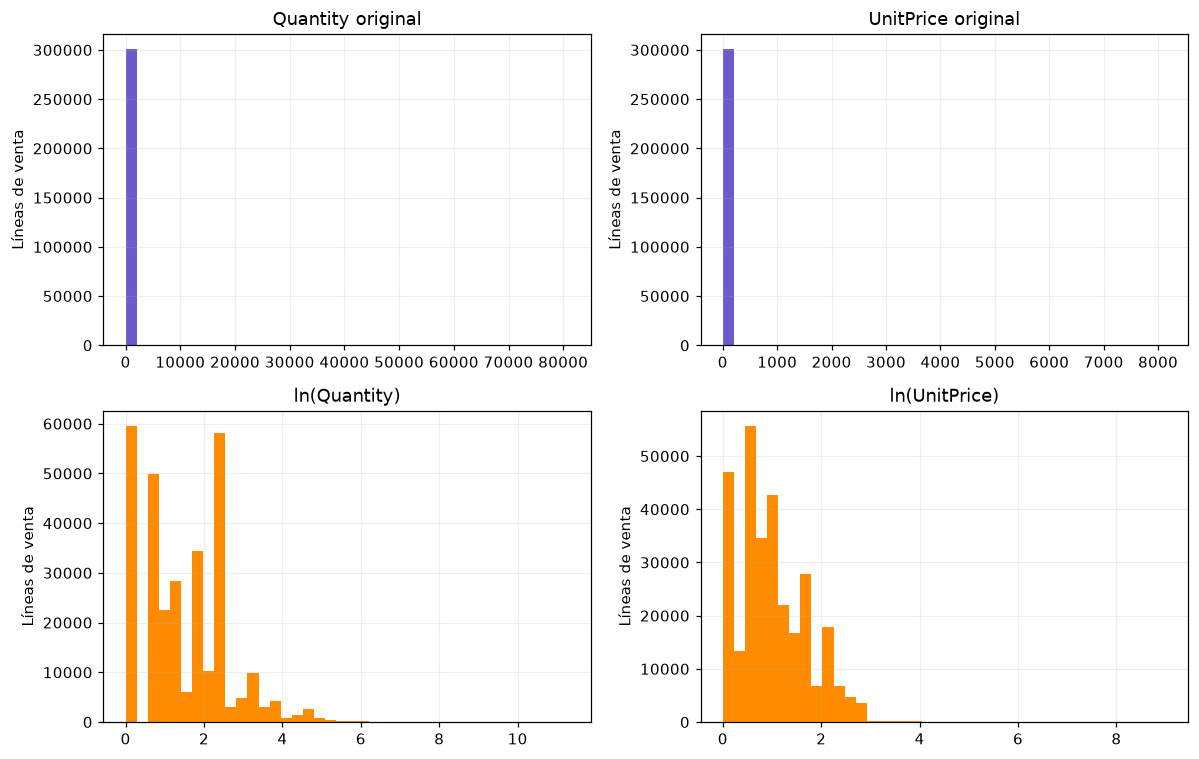

,Media,Desviación
Quantity,-0.0,1.0
UnitPrice,0.0,1.0


In [5]:
X_log = np.log(X)
escalador = StandardScaler()
X_std = escalador.fit_transform(X_log)
fig, ejes = plt.subplots(2, 2, figsize=(11, 7))
for j, variable in enumerate(variables):
    ejes[0,j].hist(X[variable], bins=40, color='slateblue')
    ejes[0,j].set_title(variable + ' original')
    ejes[1,j].hist(X_log[variable], bins=40, color='darkorange')
    ejes[1,j].set_title('ln(' + variable + ')')
    for i in range(2): ejes[i,j].set_ylabel('Líneas de venta')
plt.tight_layout(); plt.show()
display(pd.DataFrame({'Media':X_std.mean(axis=0), 'Desviación':X_std.std(axis=0)}, index=variables).round(4))
assert np.allclose(X_std.mean(axis=0), 0, atol=1e-9)
assert np.allclose(X_std.std(axis=0), 1)


## 5. Comparar de 2 a 8 grupos
Cada modelo se ajusta con todas las filas limpias. Para la silueta uso siempre las mismas 2,000 posiciones aleatorias; así el cálculo es manejable y los candidatos se comparan sobre la misma muestra. La inercia corresponde al conjunto completo y la silueta es una estimación.


,k,Inercia,Silueta,Reducción_inercia_pct
0,2,334314.5318,0.4140,NaN
1,3,209465.6729,0.4427,37.3447
2,4,161408.8931,0.4313,22.9426
3,5,128888.2091,0.4386,20.1480
4,6,106219.8490,0.4332,17.5876
5,7,93957.8242,0.3868,11.5440
6,8,83010.3513,0.4036,11.6515


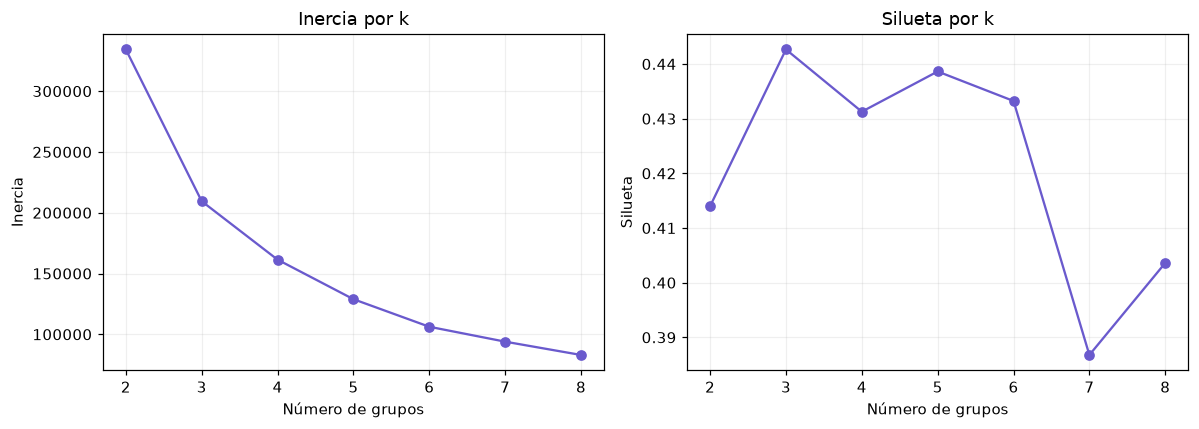

In [6]:
# Muestreo reproducible equivalente a sample(random_state=42) sobre las filas.
posiciones = pd.Series(np.arange(len(X))).sample(n=min(2000, len(X)), random_state=SEMILLA).to_numpy()
muestra = X_std[posiciones]
mediciones = []
for k in range(2, 9):
    candidato = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA)
    candidato.fit(X_std)
    grupos_muestra = candidato.predict(muestra)
    if not 1 < len(np.unique(grupos_muestra)) < len(muestra):
        raise ValueError('La muestra no permite calcular silueta; revisar sus grupos.')
    mediciones.append({'k':k, 'Inercia':candidato.inertia_,
                       'Silueta':silhouette_score(muestra, grupos_muestra)})
metricas = pd.DataFrame(mediciones)
metricas['Reducción_inercia_pct'] = -metricas['Inercia'].pct_change() * 100
display(metricas.round(4))
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for eje, metrica in zip(ejes, ['Inercia','Silueta']):
    eje.plot(metricas['k'], metricas[metrica], 'o-', color='slateblue')
    eje.set(xlabel='Número de grupos', ylabel=metrica, title=metrica + ' por k')
    eje.set_xticks(metricas['k'])
plt.tight_layout(); plt.show()


## 6. Ajustar el modelo final
Selecciono el candidato con mayor silueta y contrasto su resultado con la curva de inercia. No elijo ocho grupos solo porque reduzca más la inercia. Los números de grupo no tienen un orden comercial.


In [7]:
k_final = int(metricas.loc[metricas['Silueta'].idxmax(), 'k'])
modelo = KMeans(n_clusters=k_final, n_init=10, random_state=SEMILLA)
resultado = X.copy()
resultado['Grupo'] = modelo.fit_predict(X_std)
print('k seleccionado:', k_final)
resumen = resultado.groupby('Grupo').agg(
    lineas=('Quantity','size'), cantidad_media=('Quantity','mean'),
    cantidad_mediana=('Quantity','median'), precio_medio_GBP=('UnitPrice','mean'),
    precio_mediano_GBP=('UnitPrice','median'))
resumen['Porcentaje'] = resumen['lineas'] / len(resultado) * 100
display(resumen.round(2))
assert resumen['lineas'].sum() == len(X)


k seleccionado: 3


,lineas,cantidad_media,cantidad_mediana,precio_medio_GBP,precio_mediano_GBP,Porcentaje
Grupo,,,,,,
0,127232,20.98,12.0,2.05,1.74,42.27
1,96001,3.07,2.0,7.90,5.79,31.89
2,77789,1.99,2.0,1.96,1.95,25.84


## 7. Visualizar e interpretar en las unidades originales
Muestreo hasta 5,000 líneas solo para dibujar. A la izquierda aparecen las coordenadas usadas por K-Means y sus centroides. A la derecha se muestran cantidad y precio originales con ejes logarítmicos. Los colores identifican el mismo grupo en ambos paneles.


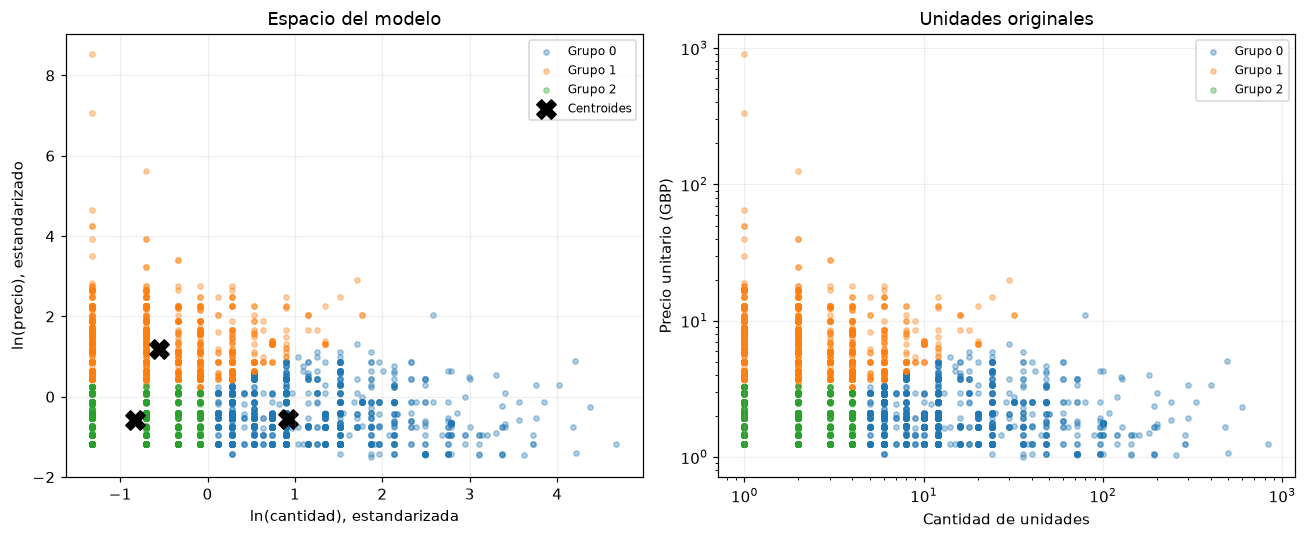

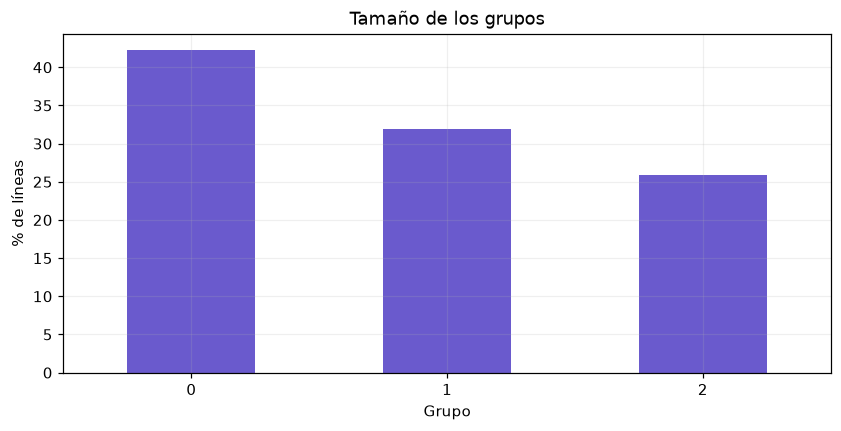

In [8]:
vista = resultado.sample(n=min(5000, len(resultado)), random_state=SEMILLA)
vista_std = escalador.transform(np.log(vista[variables]))
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
for grupo in resumen.index:
    seleccion = vista['Grupo'].eq(grupo).to_numpy()
    color = plt.get_cmap('tab10')(int(grupo))
    ejes[0].scatter(vista_std[seleccion,0], vista_std[seleccion,1], s=12, alpha=.35,
                    color=color, label=f'Grupo {grupo}')
    ejes[1].scatter(vista.loc[seleccion,'Quantity'], vista.loc[seleccion,'UnitPrice'],
                    s=12, alpha=.35, color=color, label=f'Grupo {grupo}')
centros = modelo.cluster_centers_
ejes[0].scatter(centros[:,0], centros[:,1], marker='X', s=160, color='black', label='Centroides')
ejes[0].set(xlabel='ln(cantidad), estandarizada', ylabel='ln(precio), estandarizado', title='Espacio del modelo')
ejes[1].set(xscale='log', yscale='log', xlabel='Cantidad de unidades', ylabel='Precio unitario (GBP)', title='Unidades originales')
for eje in ejes: eje.legend(fontsize=8)
plt.tight_layout(); fig.savefig(salidas/'lineas_clusters.png', bbox_inches='tight'); plt.show()
resumen['Porcentaje'].plot.bar(color='slateblue', rot=0)
plt.xlabel('Grupo'); plt.ylabel('% de líneas'); plt.title('Tamaño de los grupos'); plt.show()


## 8. Conclusión basada en la ejecución


In [9]:
mejor = metricas.loc[metricas['k'].eq(k_final)].iloc[0]
texto = [f"Después de la limpieza quedan **{len(X):,} líneas**. La mayor silueta estimada "
         f"corresponde a **k={k_final}**, con **{mejor['Silueta']:.3f}**."]
for grupo, fila in resumen.iterrows():
    texto.append(f"- Grupo {grupo}: {int(fila['lineas']):,} líneas ({fila['Porcentaje']:.1f}%). "
                 f"La cantidad mediana es {fila['cantidad_mediana']:g} unidades y el precio mediano "
                 f"es £{fila['precio_mediano_GBP']:.2f} por unidad.")
texto.append('Estos perfiles permiten comparar ventas por cantidad y precio. No identifican clientes '
             'fieles, productos rentables ni tipos de comprador. Una misma persona puede generar líneas '
             'en distintos grupos. El resultado depende del filtro de precio y de las transformaciones.')
display(Markdown('\n\n'.join(texto)))
metricas.to_csv(salidas/'lineas_metricas.csv', index=False)
resumen.to_csv(salidas/'lineas_perfiles.csv')


Después de la limpieza quedan **301,022 líneas**. La mayor silueta estimada corresponde a **k=3**, con **0.443**.

- Grupo 0: 127,232 líneas (42.3%). La cantidad mediana es 12 unidades y el precio mediano es £1.74 por unidad.

- Grupo 1: 96,001 líneas (31.9%). La cantidad mediana es 2 unidades y el precio mediano es £5.79 por unidad.

- Grupo 2: 77,789 líneas (25.8%). La cantidad mediana es 2 unidades y el precio mediano es £1.95 por unidad.

Estos perfiles permiten comparar ventas por cantidad y precio. No identifican clientes fieles, productos rentables ni tipos de comprador. Una misma persona puede generar líneas en distintos grupos. El resultado depende del filtro de precio y de las transformaciones.

## 9. Respuestas de la práctica
1. **¿Qué representa una fila?** Un producto y su cantidad dentro de una factura. No representa la factura completa ni una persona.
2. **¿Para qué sirve ln?** Permite observar mejor la parte central de distribuciones con valores extremos. Conserva el orden de los valores y no garantiza normalidad.
3. **¿Por qué StandardScaler?** Para medir las dos columnas en desviaciones estándar y evitar que la escala numérica de una domine por sí sola.
4. **¿Cómo elegir k?** Comparo la silueta, la disminución de inercia y las medianas. La mayor silueta se usa aquí como regla inicial, con el alcance limitado de una muestra.
5. **¿Precio alto significa mayor rentabilidad?** No. Faltan costos, descuentos y otros gastos. El precio unitario por sí solo no determina la ganancia.
6. **¿Qué limita el análisis?** No incorporé productos, países, fechas ni perfiles del cliente. Además, las combinaciones repetidas de cantidad y precio pesan más por aparecer en más líneas.


### Lectura del codo y la silueta

La inercia disminuye 37.3% al pasar de 2 a 3 grupos y 22.9% al pasar de 3 a 4. La mejora se reduce después de tres, lo que sugiere un codo alrededor de ese valor. La silueta estimada también favorece k=3 (0.443), frente a k=2 (0.414) y k=4 (0.431). Por eso conservo tres grupos. El grupo 0 reúne cantidades típicas mayores y precios menores; los grupos 1 y 2 tienen cantidades típicas similares, pero se distinguen por el precio. No interpreto estos perfiles como mayoristas o clientes premium porque no se analizaron esas características.
